<a href="https://colab.research.google.com/github/srihanreddy/Quantum-Hackathon/blob/main/Learning_Based_Output_Error_Mitigation_MODIFIED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Learning-Based Output Error Mitigation
**Project reference:** H. Ohno, “A direct error correction method for quantum machine learning,” *Quantum Information Processing* 22, 119 (2023). https://doi.org/10.1007/s11128-023-03863-z

## Objectives
1. **D21 — 2×2 Bars and Stripes:** mitigate noisy Born-machine probabilities and report total variation (TV) distance from the noiseless reference.
2. **D19 — Noisy sine sequences:** mitigate the output of a quantum regressor and report RMSE against the noiseless reference.
3. Compare mitigation across noise strengths and report task loss, calibration calls, and quantum resources.

**Leakage control:** calibration parameter settings / inputs are disjoint from final evaluation settings / inputs. Final evaluation circuits are never used to fit the mitigation maps.

The implementation is an educational, reproducible adaptation of learning-based output correction. It uses Ridge regression to learn a mapping from noisy outputs to noiseless outputs. The cited paper describes learning-based correction functions trained from noise-free simulator outputs; this notebook does not claim to reproduce every detail of the paper.

## 1. Environment and configuration

In [1]:
%pip -q install pennylane

In [2]:
import os, time, json, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

SEED = 42
rng = np.random.default_rng(SEED)

# Keep the first run small; increase after verifying execution.
N_QUBITS = 4
Q_DEPTH = 2
SHOTS = 512
NOISE_LEVELS = [0.02, 0.05]
N_CAL_D21 = 20
N_EVAL_D21 = 10
N_CAL_D19 = 40
N_EVAL_D19 = 40
SERIES_LENGTH = 240
CALIBRATION_FRACTION = 0.40

OUT_DIR = "/kaggle/working/output_error_mitigation_results"
os.makedirs(OUT_DIR, exist_ok=True)

print("PennyLane:", qml.__version__)
print("Output directory:", OUT_DIR)

PennyLane: 0.45.1
Output directory: /kaggle/working/output_error_mitigation_results


## 2. Shared utilities

In [3]:
def tv_distance(p, q):
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    return 0.5 * np.sum(np.abs(p - q))

def project_simplex_rows(arr, eps=1e-12):
    """Clip negative values and normalize each row to a probability simplex."""
    arr = np.asarray(arr, dtype=float)
    arr = np.clip(arr, 0.0, None) + eps
    return arr / arr.sum(axis=1, keepdims=True)

def make_mitigator(alpha=1e-3):
    # Ridge multi-output regression learns noisy output -> noiseless output.
    return Ridge(alpha=alpha)

def summarize_resources(name, qubits, depth, shots, circuit_calls,
                        calibration_calls, train_seconds, eval_seconds):
    return {
        "experiment": name,
        "qubits": qubits,
        "modes": "N/A (qubit circuit)",
        "circuit_depth_estimate": depth,
        "shots_per_circuit": shots,
        "circuit_evaluations": int(circuit_calls),
        "extra_calibration_calls": int(calibration_calls),
        "training_time_seconds": float(train_seconds),
        "inference_or_generation_time_seconds": float(eval_seconds),
    }

## 3. D21 — 2×2 Bars and Stripes Born machine

A 2×2 binary image belongs to the Bars-and-Stripes set when its rows are identical (horizontal bars) or its columns are identical (vertical stripes). The four constant images are counted once, giving six patterns.

We train a small parameterized quantum circuit on the target distribution using a simple probability-matching objective. The same parameter settings are then evaluated with noiseless and noisy simulators. Calibration settings are sampled independently from final evaluation settings.

In [4]:
def bars_and_stripes_2x2():
    patterns = set()
    # Horizontal bars: each row is constant.
    for a in [0, 1]:
        for b in [0, 1]:
            patterns.add((a, a, b, b))
    # Vertical stripes: each column is constant.
    for a in [0, 1]:
        for b in [0, 1]:
            patterns.add((a, b, a, b))
    arr = np.array(sorted(patterns), dtype=int)
    return arr

BAS = bars_and_stripes_2x2()
BAS

array([[0, 0, 0, 0],
       [0, 0, 1, 1],
       [0, 1, 0, 1],
       [1, 0, 1, 0],
       [1, 1, 0, 0],
       [1, 1, 1, 1]])

In [5]:
# The target distribution is uniform over the six valid patterns.
target_probs = np.zeros(2**N_QUBITS)
for bits in BAS:
    idx = int("".join(map(str, bits)), 2)
    target_probs[idx] = 1.0 / len(BAS)

print("Bars and Stripes patterns:", len(BAS))
print("Target support:", np.flatnonzero(target_probs))

Bars and Stripes patterns: 6
Target support: [ 0  3  5 10 12 15]


### 3.1 Quantum Born-machine circuit and noise model

In [6]:
dev_ideal = qml.device("default.qubit", wires=N_QUBITS, shots=SHOTS)

def born_ansatz(theta):
    for w in range(N_QUBITS):
        qml.RY(theta[w], wires=w)
        qml.RZ(theta[N_QUBITS + w], wires=w)
    for layer in range(Q_DEPTH):
        for w in range(N_QUBITS - 1):
            qml.CNOT(wires=[w, w + 1])
        qml.CNOT(wires=[N_QUBITS - 1, 0])
        for w in range(N_QUBITS):
            qml.RY(theta[2*N_QUBITS + layer*N_QUBITS + w], wires=w)

@qml.qnode(dev_ideal)
def born_ideal(theta):
    born_ansatz(theta)
    return qml.probs(wires=range(N_QUBITS))

def make_noisy_born_qnode(noise_p):
    dev = qml.device("default.mixed", wires=N_QUBITS, shots=SHOTS)
    @qml.qnode(dev)
    def circuit(theta):
        for w in range(N_QUBITS):
            qml.RY(theta[w], wires=w)
            qml.DepolarizingChannel(noise_p, wires=w)
            qml.RZ(theta[N_QUBITS + w], wires=w)
            qml.DepolarizingChannel(noise_p, wires=w)
        for layer in range(Q_DEPTH):
            for w in range(N_QUBITS - 1):
                qml.CNOT(wires=[w, w + 1])
                qml.DepolarizingChannel(noise_p, wires=w)
                qml.DepolarizingChannel(noise_p, wires=w + 1)
            qml.CNOT(wires=[N_QUBITS - 1, 0])
            qml.DepolarizingChannel(noise_p, wires=N_QUBITS - 1)
            qml.DepolarizingChannel(noise_p, wires=0)
            for w in range(N_QUBITS):
                qml.RY(theta[2*N_QUBITS + layer*N_QUBITS + w], wires=w)
                qml.DepolarizingChannel(noise_p, wires=w)
        return qml.probs(wires=range(N_QUBITS))
    return circuit

N_PARAMS = 2*N_QUBITS + Q_DEPTH*N_QUBITS

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


### 3.2 Fit Born-machine parameters on the training objective

In [7]:
# A lightweight parameter search using SPSA-like random perturbations.
# The objective is evaluated on the ideal simulator; noisy output correction
# is learned later from an independent calibration set.
def born_loss(theta):
    p = np.asarray(born_ideal(theta), dtype=float)
    return float(np.mean((p - target_probs)**2))

theta = rng.normal(0, 0.25, size=N_PARAMS)
best_loss = born_loss(theta)
for step in range(35):
    direction = rng.choice([-1.0, 1.0], size=N_PARAMS)
    lr = 0.08 / (1 + step/80)
    c = 0.08 / (1 + step/100)
    plus = born_loss(theta + c*direction)
    minus = born_loss(theta - c*direction)
    grad_est = ((plus - minus)/(2*c)) * direction
    candidate = theta - lr*grad_est
    loss = born_loss(candidate)
    if loss < best_loss:
        theta, best_loss = candidate, loss

print("Best ideal training objective:", best_loss)
p_ideal_d21 = np.asarray(born_ideal(theta), dtype=float)
print("Ideal Born output sums to:", p_ideal_d21.sum())

Best ideal training objective: 0.03727102279663086
Ideal Born output sums to: 1.0


### 3.3 Independent calibration and evaluation circuits

In [8]:
# Generate disjoint nearby circuit parameter settings.
# Calibration is used only to fit the correction model.
# Evaluation settings are held out and never enter mitigation fitting.
theta_cal = theta + rng.normal(0, 0.35, size=(N_CAL_D21, N_PARAMS))
theta_eval = theta + rng.normal(0, 0.35, size=(N_EVAL_D21, N_PARAMS))

ideal_cal = np.array([born_ideal(t) for t in theta_cal])
ideal_eval = np.array([born_ideal(t) for t in theta_eval])

d21_rows = []
d21_resources = []
d21_curves = {}

for noise_p in NOISE_LEVELS:
    noisy_qnode = make_noisy_born_qnode(noise_p)
    t0 = time.perf_counter()
    noisy_cal = np.array([noisy_qnode(t) for t in theta_cal])
    mitigator = make_mitigator(alpha=1e-3)
    mitigator.fit(noisy_cal, ideal_cal)
    train_time = time.perf_counter() - t0

    t1 = time.perf_counter()
    noisy_eval = np.array([noisy_qnode(t) for t in theta_eval])
    mitigated_eval = project_simplex_rows(mitigator.predict(noisy_eval))
    eval_time = time.perf_counter() - t1

    raw_tv = np.mean([tv_distance(a, b) for a, b in zip(noisy_eval, ideal_eval)])
    mit_tv = np.mean([tv_distance(a, b) for a, b in zip(mitigated_eval, ideal_eval)])
    raw_task = np.mean((noisy_eval - ideal_eval)**2)
    mit_task = np.mean((mitigated_eval - ideal_eval)**2)

    d21_rows.append({
        "noise_probability": noise_p,
        "raw_mean_TV_distance": raw_tv,
        "mitigated_mean_TV_distance": mit_tv,
        "raw_probability_MSE": raw_task,
        "mitigated_probability_MSE": mit_task,
    })
    d21_curves[noise_p] = (raw_tv, mit_tv)
    d21_resources.append(summarize_resources(
        "D21 Born machine", N_QUBITS, Q_DEPTH, SHOTS,
        (N_CAL_D21 + N_EVAL_D21) * (1 + len(NOISE_LEVELS)),
        N_CAL_D21, train_time, eval_time
    ))

d21_results = pd.DataFrame(d21_rows)
display(d21_results)

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


,noise_probability,raw_mean_TV_distance,mitigated_mean_TV_distance,raw_probability_MSE,mitigated_probability_MSE
0,0.02,0.243945,0.136245,0.003516,0.000690
1,0.05,0.444336,0.189312,0.011002,0.001214


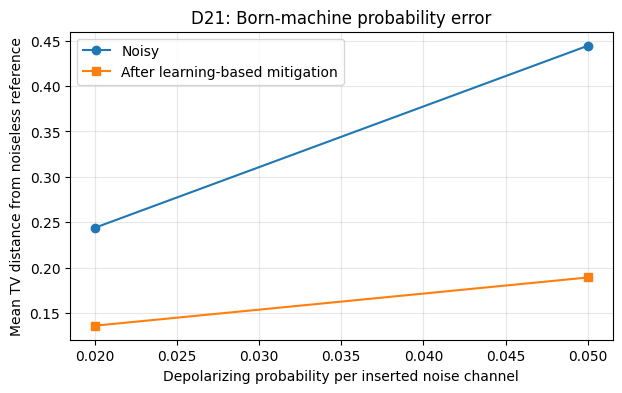

In [9]:
x = np.arange(len(NOISE_LEVELS))
raw = [d21_curves[p][0] for p in NOISE_LEVELS]
mit = [d21_curves[p][1] for p in NOISE_LEVELS]
plt.figure(figsize=(7,4))
plt.plot(NOISE_LEVELS, raw, marker="o", label="Noisy")
plt.plot(NOISE_LEVELS, mit, marker="s", label="After learning-based mitigation")
plt.xlabel("Depolarizing probability per inserted noise channel")
plt.ylabel("Mean TV distance from noiseless reference")
plt.title("D21: Born-machine probability error")
plt.grid(alpha=.3); plt.legend(); plt.show()

## 4. D19 — Noisy sine sequence quantum regressor

We create a reproducible noisy sine sequence. The regressor maps a scalar input \(x\) to a scalar prediction using a parameterized one-qubit circuit. The noiseless circuit defines the reference output. The noisy circuit is evaluated under depolarizing noise.

Calibration inputs are selected from a dedicated calibration partition. The mitigation model is fitted only on pairs `(noisy calibration prediction, noiseless calibration prediction)`. The final test partition is evaluated only after mitigation has been fitted.

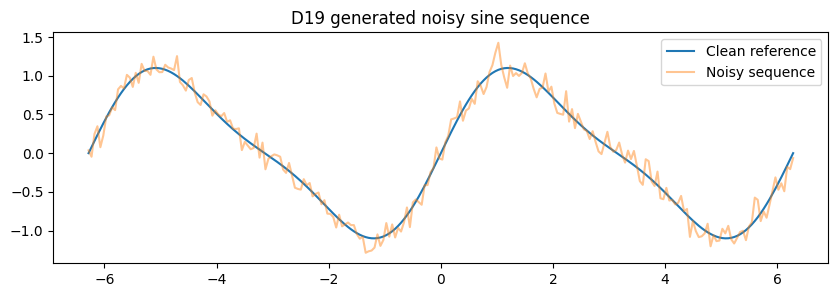

In [10]:
def generate_noisy_sine(n=SERIES_LENGTH, seed=SEED):
    r = np.random.default_rng(seed)
    x = np.linspace(-2*np.pi, 2*np.pi, n)
    clean = np.sin(x) + 0.25*np.sin(2*x)
    observed = clean + r.normal(0, 0.12, size=n)
    return x, clean, observed

x_all, y_clean, y_observed = generate_noisy_sine()
plt.figure(figsize=(10,3))
plt.plot(x_all, y_clean, label="Clean reference")
plt.plot(x_all, y_observed, alpha=.45, label="Noisy sequence")
plt.legend(); plt.title("D19 generated noisy sine sequence"); plt.show()

# Chronological split: train / calibration / final test.
n = len(x_all)
train_end = int(0.50*n)
cal_end = int(0.75*n)
x_train, y_train = x_all[:train_end], y_clean[:train_end]
x_cal, y_cal = x_all[train_end:cal_end], y_clean[train_end:cal_end]
x_test, y_test = x_all[cal_end:], y_clean[cal_end:]

# Reduce circuit input to [-pi, pi].
def encode_x(x):
    return np.asarray(x) / 2.0

### 4.1 Quantum regressor circuit

In [11]:
dev_reg_ideal = qml.device("default.qubit", wires=1, shots=SHOTS)

@qml.qnode(dev_reg_ideal)
def reg_ideal_qnode(x, weights):
    qml.RY(encode_x(x), wires=0)
    qml.RY(weights[0], wires=0)
    qml.RZ(weights[1], wires=0)
    qml.RY(weights[2], wires=0)
    return qml.expval(qml.PauliZ(0))

def make_noisy_regressor(noise_p):
    dev = qml.device("default.mixed", wires=1, shots=SHOTS)
    @qml.qnode(dev)
    def circuit(x, weights):
        qml.RY(encode_x(x), wires=0)
        qml.DepolarizingChannel(noise_p, wires=0)
        qml.RY(weights[0], wires=0)
        qml.DepolarizingChannel(noise_p, wires=0)
        qml.RZ(weights[1], wires=0)
        qml.DepolarizingChannel(noise_p, wires=0)
        qml.RY(weights[2], wires=0)
        qml.DepolarizingChannel(noise_p, wires=0)
        return qml.expval(qml.PauliZ(0))
    return circuit

# Fit the quantum regressor on the training partition only.
from scipy.optimize import minimize

# Deterministic subset to reduce quantum circuit evaluations.
train_pick = np.linspace(0, len(x_train)-1, min(50, len(x_train)), dtype=int)
x_train_small = x_train[train_pick]
y_train_small = y_train[train_pick]

def reg_train_loss(w):
    preds = np.array([reg_ideal_qnode(x, w) for x in x_train_small])
    return mean_squared_error(y_train_small, preds)

t0 = time.perf_counter()
opt = minimize(reg_train_loss, x0=np.array([0.2, 0.1, -0.2]),
               method="Nelder-Mead", options={"maxiter": 60})
reg_weights = opt.x
reg_train_seconds = time.perf_counter() - t0
print("Regressor training MSE:", opt.fun)
print("Weights:", reg_weights)

def ideal_reg_predictions(xs):
    return np.array([reg_ideal_qnode(x, reg_weights) for x in xs])

ideal_cal_reg = ideal_reg_predictions(x_cal)
ideal_test_reg = ideal_reg_predictions(x_test)

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


Regressor training MSE: 1.922076186813614
Weights: [ 0.21027316  0.09915639 -0.19869373]


### 4.2 Fit mitigation using calibration data only

In [12]:
d19_rows = []
d19_resources = []
d19_curves = {}

for noise_p in NOISE_LEVELS:
    noisy_reg = make_noisy_regressor(noise_p)

    t0 = time.perf_counter()
    noisy_cal_reg = np.array([noisy_reg(x, reg_weights) for x in x_cal])
    # Polynomial Ridge allows a smooth nonlinear correction while remaining
    # a learned output map. The final test values are not used for fitting.
    mitigator = make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                              Ridge(alpha=1e-2))
    mitigator.fit(noisy_cal_reg.reshape(-1,1), ideal_cal_reg)
    mitigation_train_time = time.perf_counter() - t0

    t1 = time.perf_counter()
    noisy_test_reg = np.array([noisy_reg(x, reg_weights) for x in x_test])
    mitigated_test_reg = mitigator.predict(noisy_test_reg.reshape(-1,1))
    eval_time = time.perf_counter() - t1

    raw_rmse = mean_squared_error(ideal_test_reg, noisy_test_reg)**0.5
    mit_rmse = mean_squared_error(ideal_test_reg, mitigated_test_reg)**0.5
    raw_task_rmse = mean_squared_error(y_test, noisy_test_reg)**0.5
    mit_task_rmse = mean_squared_error(y_test, mitigated_test_reg)**0.5

    d19_rows.append({
        "noise_probability": noise_p,
        "raw_RMSE_vs_noiseless_quantum_reference": raw_rmse,
        "mitigated_RMSE_vs_noiseless_quantum_reference": mit_rmse,
        "raw_task_RMSE_vs_clean_sine": raw_task_rmse,
        "mitigated_task_RMSE_vs_clean_sine": mit_task_rmse,
    })
    d19_curves[noise_p] = (raw_rmse, mit_rmse, noisy_test_reg, mitigated_test_reg)
    d19_resources.append(summarize_resources(
        "D19 quantum regressor", 1, 4, SHOTS,
        len(x_cal) + len(x_test), len(x_cal),
        reg_train_seconds + mitigation_train_time, eval_time
    ))

d19_results = pd.DataFrame(d19_rows)
display(d19_results)

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


,noise_probability,raw_RMSE_vs_noiseless_quantum_reference,mitigated_RMSE_vs_noiseless_quantum_reference,raw_task_RMSE_vs_clean_sine,mitigated_task_RMSE_vs_clean_sine
0,0.02,0.086942,0.182195,0.319388,0.337256
1,0.05,0.181479,0.068700,0.334963,0.330309


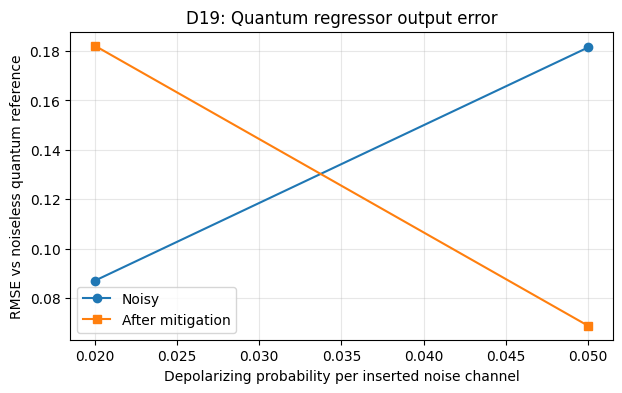

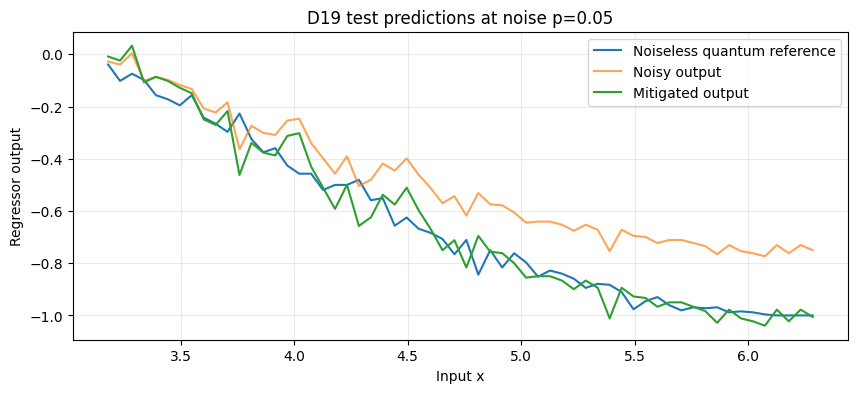

In [13]:
plt.figure(figsize=(7,4))
plt.plot(NOISE_LEVELS, d19_results["raw_RMSE_vs_noiseless_quantum_reference"],
         marker="o", label="Noisy")
plt.plot(NOISE_LEVELS, d19_results["mitigated_RMSE_vs_noiseless_quantum_reference"],
         marker="s", label="After mitigation")
plt.xlabel("Depolarizing probability per inserted noise channel")
plt.ylabel("RMSE vs noiseless quantum reference")
plt.title("D19: Quantum regressor output error")
plt.grid(alpha=.3); plt.legend(); plt.show()

# Show final test predictions for the highest noise setting.
p_show = NOISE_LEVELS[-1]
raw_pred = d19_curves[p_show][2]
mit_pred = d19_curves[p_show][3]
plt.figure(figsize=(10,4))
plt.plot(x_test, ideal_test_reg, label="Noiseless quantum reference")
plt.plot(x_test, raw_pred, label="Noisy output", alpha=.7)
plt.plot(x_test, mit_pred, label="Mitigated output")
plt.xlabel("Input x"); plt.ylabel("Regressor output")
plt.title(f"D19 test predictions at noise p={p_show}")
plt.legend(); plt.grid(alpha=.25); plt.show()

## 5. Combined results and quantum resource accounting

In [14]:
resource_df = pd.DataFrame(d21_resources + d19_resources)
display(resource_df)

# Task-loss summary tables.
display(d21_results)
display(d19_results)

# Export reproducible outputs.
d21_results.to_csv(os.path.join(OUT_DIR, "D21_Born_machine_results.csv"), index=False)
d19_results.to_csv(os.path.join(OUT_DIR, "D19_quantum_regressor_results.csv"), index=False)
resource_df.to_csv(os.path.join(OUT_DIR, "quantum_resource_analysis.csv"), index=False)

summary = {
    "project": "Learning-Based Output Error Mitigation",
    "seed": SEED,
    "qubits_Born_machine": N_QUBITS,
    "qubits_regressor": 1,
    "depth_Born_machine_estimate": Q_DEPTH * (N_QUBITS + 1) + 2,
    "depth_regressor_estimate": 4,
    "shots_per_circuit": SHOTS,
    "noise_levels": NOISE_LEVELS,
    "calibration_separate_from_evaluation": True,
    "note": "Depth values are structural estimates; verify decomposed device-specific depth before hardware claims."
}
with open(os.path.join(OUT_DIR, "experiment_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

print("Saved results to:", OUT_DIR)

,experiment,qubits,modes,circuit_depth_estimate,shots_per_circuit,circuit_evaluations,extra_calibration_calls,training_time_seconds,inference_or_generation_time_seconds
0,D21 Born machine,4,N/A (qubit circuit),2,512,90,20,1.855210,0.852031
1,D21 Born machine,4,N/A (qubit circuit),2,512,90,20,1.325113,0.737266
2,D19 quantum regressor,1,N/A (qubit circuit),4,512,120,60,76.751893,0.516343
3,D19 quantum regressor,1,N/A (qubit circuit),4,512,120,60,76.710991,0.504824


,noise_probability,raw_mean_TV_distance,mitigated_mean_TV_distance,raw_probability_MSE,mitigated_probability_MSE
0,0.02,0.243945,0.136245,0.003516,0.000690
1,0.05,0.444336,0.189312,0.011002,0.001214


,noise_probability,raw_RMSE_vs_noiseless_quantum_reference,mitigated_RMSE_vs_noiseless_quantum_reference,raw_task_RMSE_vs_clean_sine,mitigated_task_RMSE_vs_clean_sine
0,0.02,0.086942,0.182195,0.319388,0.337256
1,0.05,0.181479,0.068700,0.334963,0.330309


Saved results to: /kaggle/working/output_error_mitigation_results


## 6. Interpretation checklist

When discussing results, answer these questions from your actual output tables:

1. Does learning-based mitigation reduce D21 mean TV distance at each noise strength?
2. Does it reduce D21 probability MSE?
3. Does mitigation reduce D19 RMSE against the noiseless quantum reference?
4. Does it also improve task RMSE against the clean sine signal?
5. Does the mitigation benefit shrink or grow as noise strength increases?
6. How many extra calibration circuits were required?
7. What is the trade-off between calibration cost and output accuracy?

Do not claim mitigation is successful if a metric becomes worse. Report negative or mixed results honestly.

## 7. Limitations

- The experiments use PennyLane simulators and synthetic datasets, not physical quantum hardware.
- `default.mixed` simulates depolarizing channels on CPU; a Kaggle GPU does not automatically accelerate these circuits.
- Shot-based estimates introduce sampling variance.
- The learned correction is trained for the selected noise settings and circuit family; generalization to other devices or noise channels is not guaranteed.
- Circuit-depth values in the resource table are structural estimates, not transpiled hardware depth.
- D21 uses a compact 4-qubit Born-machine demonstration. D19 uses a one-qubit variational regressor.
- The method is an educational adaptation inspired by the cited learning-based output correction approach, not an exact reproduction of the paper.

## 8. Reference

Ohno, H. (2023). *A direct error correction method for quantum machine learning*. Quantum Information Processing, 22, 119. https://doi.org/10.1007/s11128-023-03863-z